# Analyse Exploratoire

### Import des modules

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import shap
from sklearn.inspection import permutation_importance
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score, f1_score, roc_curve, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve, fbeta_score

D:\Taf\Training\OpenClassrooms\Projets\Projet 4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Fusion des fichiers de données en fichier central

In [48]:
sirh = pd.read_csv("extrait_sirh.csv")
sondage = pd.read_csv("extrait_sondage.csv", dtype={"code_sondage": str})
evals = pd.read_csv("extrait_eval.csv")

sondage["id_employee"] = sondage["code_sondage"].astype(int)
evals["id_employee"] = evals["eval_number"].str.replace("E_", "", regex=False).astype(int)

# Vérification des ids dans les 3 fichiers
ids_sirh = set(sirh["id_employee"])
ids_sondage = set(sondage["id_employee"])
ids_eval = set(evals["id_employee"])

ids_communs = ids_sirh & ids_sondage & ids_eval   # intersection des 3 ensembles
print(f"IDs présents dans les 3 fichiers : {len(ids_communs)}")

for nom, ids in [("sirh", ids_sirh), ("sondage", ids_sondage), ("eval", ids_eval)]:
    manquants = ids - ids_communs   # ids de ce fichier absents d'au moins un autre
    print(f"{nom} : {len(ids)} IDs, dont {len(manquants)} absents d'au moins un autre fichier",
          sorted(manquants)[:10] if manquants else "")

# Vérification de doublons
for nom, df in [("sirh", sirh), ("sondage", sondage), ("eval", evals)]:
    assert df["id_employee"].is_unique, f"Doublons de clé dans {nom}"

df_central = (
    sirh
    .merge(sondage.drop(columns="code_sondage"), on="id_employee", how="inner", validate="one_to_one")
    .merge(evals.drop(columns="eval_number"), on="id_employee", how="inner", validate="one_to_one")
)

print(df_central.shape)  # (1470, 32)
df_central.head()

IDs présents dans les 3 fichiers : 1470
sirh : 1470 IDs, dont 0 absents d'au moins un autre fichier 
sondage : 1470 IDs, dont 0 absents d'au moins un autre fichier 
eval : 1470 IDs, dont 0 absents d'au moins un autre fichier 
(1470, 32)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4,Oui,0,0,1,1,2,Infra & Cloud,Y,Occasionnel,0,5,2,3,2,4,1,1,3,Oui,11 %
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7,Non,1,3,1,8,1,Infra & Cloud,Y,Frequent,1,7,3,2,2,2,4,3,4,Non,23 %
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0,Oui,0,3,1,2,2,Autre,Y,Occasionnel,0,0,4,2,1,3,2,3,3,Oui,15 %
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7,Non,0,3,1,3,4,Infra & Cloud,Y,Frequent,3,0,4,3,1,3,3,3,3,Oui,11 %
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2,Non,1,3,1,2,1,Transformation Digitale,Y,Occasionnel,2,2,1,3,1,2,4,3,3,Non,12 %


### Statistiques descriptives fichiers sources

In [49]:
fichiers = {
    "sirh": pd.read_csv("extrait_sirh.csv"),
    "sondage": pd.read_csv("extrait_sondage.csv", dtype={"code_sondage": str}),
    "eval": pd.read_csv("extrait_eval.csv"),
}

# Numérisation colonne augmentation salaire
fichiers["eval"]["augementation_salaire_precedente"] = (
    fichiers["eval"]["augementation_salaire_precedente"].str.replace("%", "").str.strip().astype(int)
)

# Exclusion identifiants de l'analyse
cles = {"id_employee", "code_sondage", "eval_number"}
pd.set_option("display.width", 200, "display.max_columns", 50)

for nom, df in fichiers.items():
    print(f"\n{'=' * 20} {nom.upper()} {df.shape} {'=' * 20}")

    # Qualité : valeurs manquantes et doublons
    print("Valeurs manquantes :", int(df.isna().sum().sum()),
          "| Lignes dupliquées :", int(df.duplicated().sum()))

    data = df.drop(columns=[c for c in df.columns if c in cles])

    # Variables numériques
    num = data.select_dtypes("number")
    if not num.empty:
        print("\n-- Numériques --")
        print(num.describe().T.round(2))

    # Variables catégorielles : nombre de modalités et répartition en %
    cat = data.select_dtypes(exclude="number")
    for col in cat.columns:
        print(f"\n-- {col} ({cat[col].nunique()} modalités) --")
        print(cat[col].value_counts(normalize=True).mul(100).round(1)
              .astype(str).add(" %").to_string())


==================== SIRH (1470, 12) ====================
Valeurs manquantes : 0 | Lignes dupliquées : 0

-- Numériques --
                                 count     mean      std     min     25%     50%     75%      max
age                             1470.0    36.92     9.14    18.0    30.0    36.0    43.0     60.0
revenu_mensuel                  1470.0  6502.93  4707.96  1009.0  2911.0  4919.0  8379.0  19999.0
nombre_experiences_precedentes  1470.0     2.69     2.50     0.0     1.0     2.0     4.0      9.0
nombre_heures_travailless       1470.0    80.00     0.00    80.0    80.0    80.0    80.0     80.0
annee_experience_totale         1470.0    11.28     7.78     0.0     6.0    10.0    15.0     40.0
annees_dans_l_entreprise        1470.0     7.01     6.13     0.0     3.0     5.0     9.0     40.0
annees_dans_le_poste_actuel     1470.0     4.23     3.62     0.0     2.0     3.0     7.0     18.0

-- genre (2 modalités) --
genre
M    60.0 %
F    40.0 %

-- statut_marital (3 modalités) --

### Statistiques descriptives fichier central

In [50]:
# 1. Moyenne de chaque variable numérique : partis vs restés
num_cols = df_central.select_dtypes("number").columns.drop("id_employee")
comp = df_central.groupby("a_quitte_l_entreprise")[num_cols].mean().T.round(2)
comp["ecart_%"] = ((comp["Oui"] / comp["Non"] - 1) * 100).round(1)
print(comp.sort_values("ecart_%", key=abs, ascending=False))

# 2. Taux de départ par modalité des variables catégorielles
for col in ["heure_supplementaires", "statut_marital", "departement", "poste",
            "frequence_deplacement", "genre", "domaine_etude"]:
    taux = (df_central["a_quitte_l_entreprise"].eq("Oui")
            .groupby(df_central[col]).mean().mul(100).round(1))
    print(f"\n-- Taux de départ (%) par {col} --")
    print(taux.sort_values(ascending=False).to_string())

# 3. Paires de variables fortement corrélées (|r| > 0.5)
corr = df_central[num_cols].corr()
masque = np.triu(np.ones(corr.shape, dtype=bool), k=1)  # chaque paire une seule fois
paires = corr.where(masque).stack()
print(paires[paires.abs() > 0.5].sort_values(key=abs, ascending=False).round(2))

a_quitte_l_entreprise                          Non      Oui  ecart_%
nombre_participation_pee                      0.85     0.53    -37.6
annees_dans_le_poste_actuel                   4.48     2.90    -35.3
annes_sous_responsable_actuel                 4.37     2.85    -34.8
annee_experience_totale                      11.86     8.24    -30.5
annees_dans_l_entreprise                      7.37     5.13    -30.4
revenu_mensuel                             6832.74  4787.09    -29.9
niveau_hierarchique_poste                     2.15     1.64    -23.7
distance_domicile_travail                     8.92    10.63     19.2
annees_depuis_la_derniere_promotion           2.23     1.95    -12.6
satisfaction_employee_nature_travail          2.78     2.47    -11.2
satisfaction_employee_environnement           2.77     2.46    -11.2
nombre_experiences_precedentes                2.65     2.94     10.9
age                                          37.56    33.61    -10.5
note_evaluation_precedente        

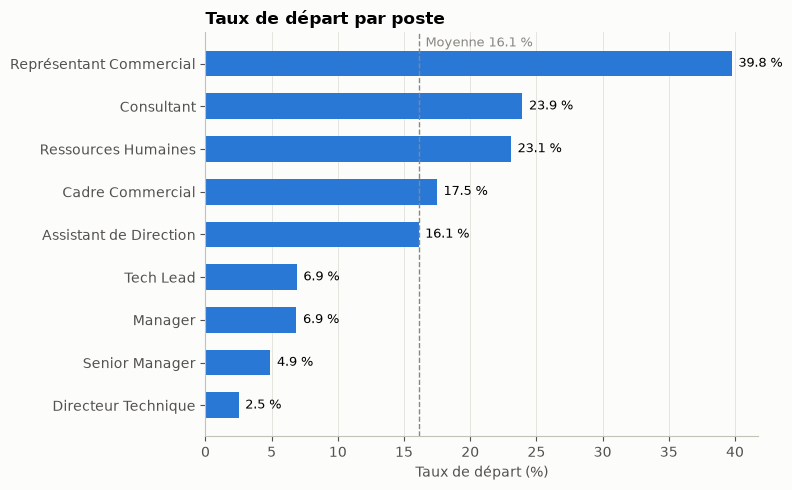

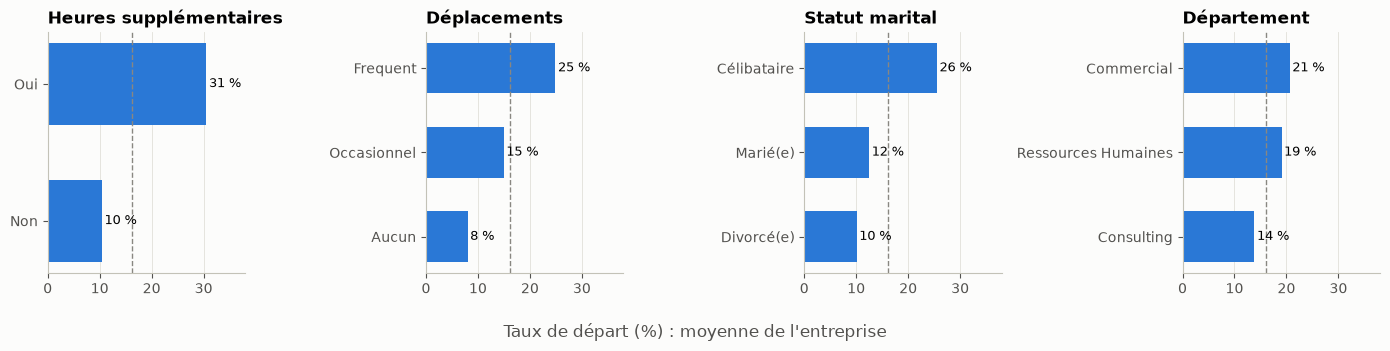

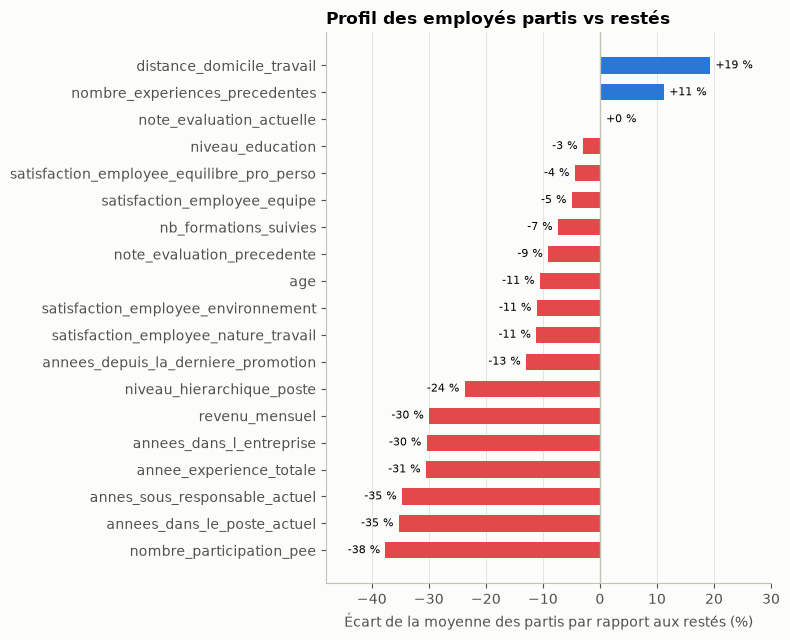

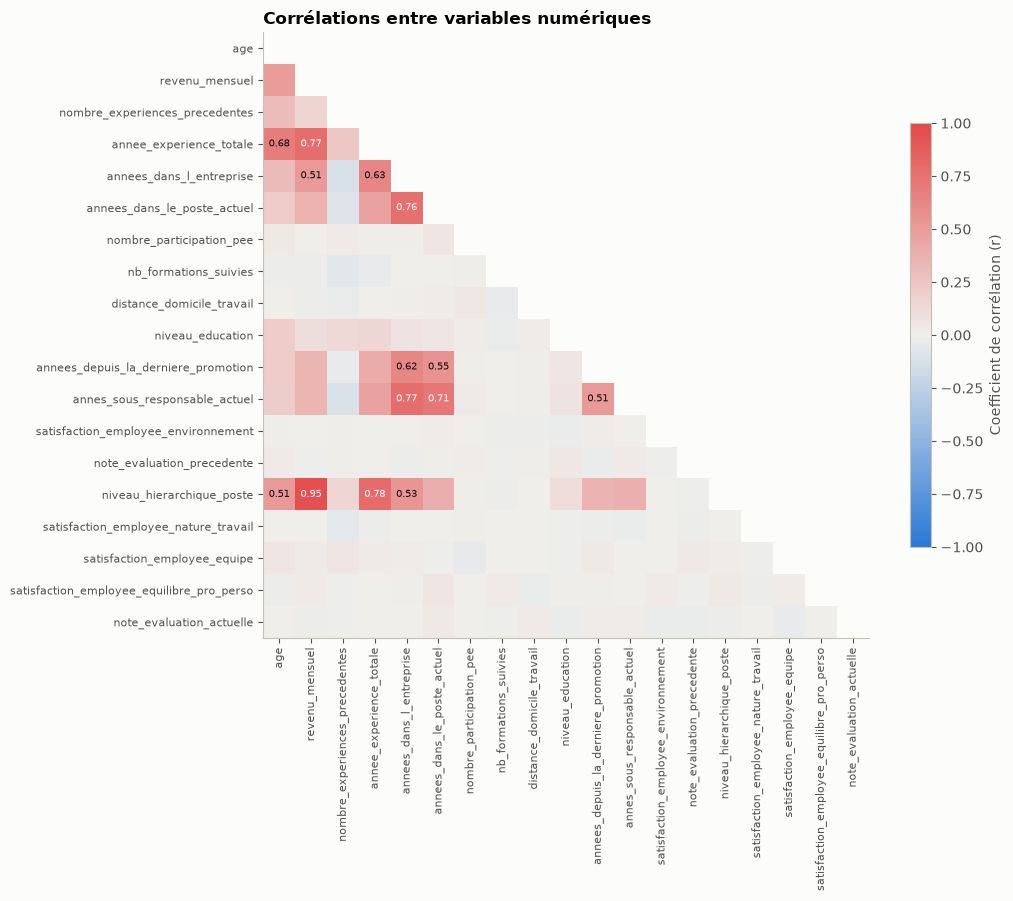

In [51]:
# ---------- Style commun ----------
BLEU, ROUGE, GRIS = "#2a78d6", "#e34948", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10,
})

df = df_central.drop(columns=["nombre_heures_travailless",
                              "nombre_employee_sous_responsabilite", "ayant_enfants"])
df["parti"] = df["a_quitte_l_entreprise"].eq("Oui")
taux_global = df["parti"].mean() * 100
num_cols = df.select_dtypes("number").columns.drop("id_employee")

def taux_depart(col):
    return df.groupby(col)["parti"].mean().mul(100).sort_values()

# ---------- 1. Taux de départ par poste ----------
fig, ax = plt.subplots(figsize=(8, 5))
t = taux_depart("poste")
ax.barh(t.index, t.values, color=BLEU, height=0.6)
ax.axvline(taux_global, color=GRIS, ls="--", lw=1)
ax.text(taux_global + 0.5, len(t) - 0.6, f"Moyenne {taux_global:.1f} %", color=GRIS, fontsize=9)
for y, v in enumerate(t.values):
    ax.text(v + 0.5, y, f"{v:.1f} %", va="center", fontsize=9)
ax.set_xlabel("Taux de départ (%)")
ax.set_title("Taux de départ par poste", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()

# ---------- 2. Taux de départ par facteur ----------
facteurs = {"heure_supplementaires": "Heures supplémentaires",
            "frequence_deplacement": "Déplacements",
            "statut_marital": "Statut marital",
            "departement": "Département"}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True)
for ax, (col, titre) in zip(axes, facteurs.items()):
    t = taux_depart(col)
    ax.barh(t.index, t.values, color=BLEU, height=0.6)
    ax.axvline(taux_global, color=GRIS, ls="--", lw=1)
    for y, v in enumerate(t.values):
        ax.text(v + 0.5, y, f"{v:.0f} %", va="center", fontsize=9)
    ax.set_title(titre, loc="left", fontweight="bold")
    ax.grid(axis="y", visible=False)
axes[0].set_xlim(0, 38)
fig.supxlabel("Taux de départ (%) : moyenne de l'entreprise", color="#52514e")
fig.tight_layout()

# ---------- 3. Écart des moyennes : partis vs restés ----------
moy = df.groupby("parti")[num_cols].mean()
ecart = ((moy.loc[True] / moy.loc[False] - 1) * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(ecart.index, ecart.values, height=0.6,
        color=np.where(ecart.values < 0, ROUGE, BLEU))
ax.axvline(0, color="#c3c2b7", lw=1)
for y, v in enumerate(ecart.values):
    ax.text(v + (1 if v >= 0 else -1), y, f"{v:+.0f} %", va="center",
            ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlim(-48, 30)
ax.set_xlabel("Écart de la moyenne des partis par rapport aux restés (%)")
ax.set_title("Profil des employés partis vs restés", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()

# ---------- 4. Matrice de corrélation ----------
corr = df[num_cols].corr()
masque = np.triu(np.ones(corr.shape, dtype=bool))  # on cache la moitié redondante
cmap = LinearSegmentedColormap.from_list("div", [BLEU, "#f0efec", ROUGE])
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(np.ma.masked_where(masque, corr), cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(i):
        r = corr.iloc[i, j]
        if abs(r) >= 0.5:  # on n'écrit que les corrélations fortes
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(r) > 0.7 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.7, label="Coefficient de corrélation (r)")
ax.set_title("Corrélations entre variables numériques", loc="left", fontweight="bold")
fig.tight_layout()

plt.show()

### Nettoyage de données

In [52]:
# Retirer les colonnes constantes (même valeur pour tout le monde)
df_central = df_central.drop(columns=["nombre_heures_travailless",
                              "nombre_employee_sous_responsabilite", "ayant_enfants"], errors="ignore")

# "11 %" -> 11 (numérique)
df_central["augementation_salaire_precedente"] = (
    df_central["augementation_salaire_precedente"].str.replace("%", "").str.strip().astype(int)
)

# Variable corrélées
df_central = df_central.drop(columns=[
    "niveau_hierarchique_poste", "note_evaluation_actuelle", "annees_dans_l_entreprise",
], errors="ignore")

In [53]:
# Matrice de corrélation de Pearson
SEUIL = 0.7

features_num = df_central.select_dtypes("number").columns.drop("id_employee")
cible = df_central["a_quitte_l_entreprise"].map({"Oui": 1, "Non": 0})

# 1. Matrice de corrélation de Pearson
corr = df_central[features_num].corr(method="pearson")

# 2. Paires au-dessus du seuil (triangle supérieur : chaque paire une seule fois)
haut = np.triu(np.ones(corr.shape, dtype=bool), k=1)
paires = corr.where(haut).stack()
paires = paires[paires.abs() > SEUIL].sort_values(key=abs, ascending=False)
print(f"Paires avec |r| > {SEUIL} :")
print(paires.round(2).to_string() if len(paires) else "aucune")

# 3. Dans chaque paire, on supprime la feature la moins liée à la cible
lien_cible = df_central[features_num].corrwith(cible).abs()
a_supprimer = set()
for (var1, var2), r in paires.items():
    if var1 in a_supprimer or var2 in a_supprimer:
        continue   # paire déjà réglée par une suppression précédente
    perdante = var1 if lien_cible[var1] < lien_cible[var2] else var2
    gagnante = var2 if perdante == var1 else var1
    a_supprimer.add(perdante)
    print(f"{var1} / {var2} (r = {r:.2f}) -> on supprime {perdante} "
          f"(lien avec la cible {lien_cible[perdante]:.3f} contre {lien_cible[gagnante]:.3f})")

print("\nÀ considérer pour suppression :", sorted(a_supprimer))

Paires avec |r| > 0.7 :
revenu_mensuel               annee_experience_totale          0.77
annees_dans_le_poste_actuel  annes_sous_responsable_actuel    0.71
revenu_mensuel / annee_experience_totale (r = 0.77) -> on supprime revenu_mensuel (lien avec la cible 0.160 contre 0.171)
annees_dans_le_poste_actuel / annes_sous_responsable_actuel (r = 0.71) -> on supprime annes_sous_responsable_actuel (lien avec la cible 0.156 contre 0.161)

À considérer pour suppression : ['annes_sous_responsable_actuel', 'revenu_mensuel']


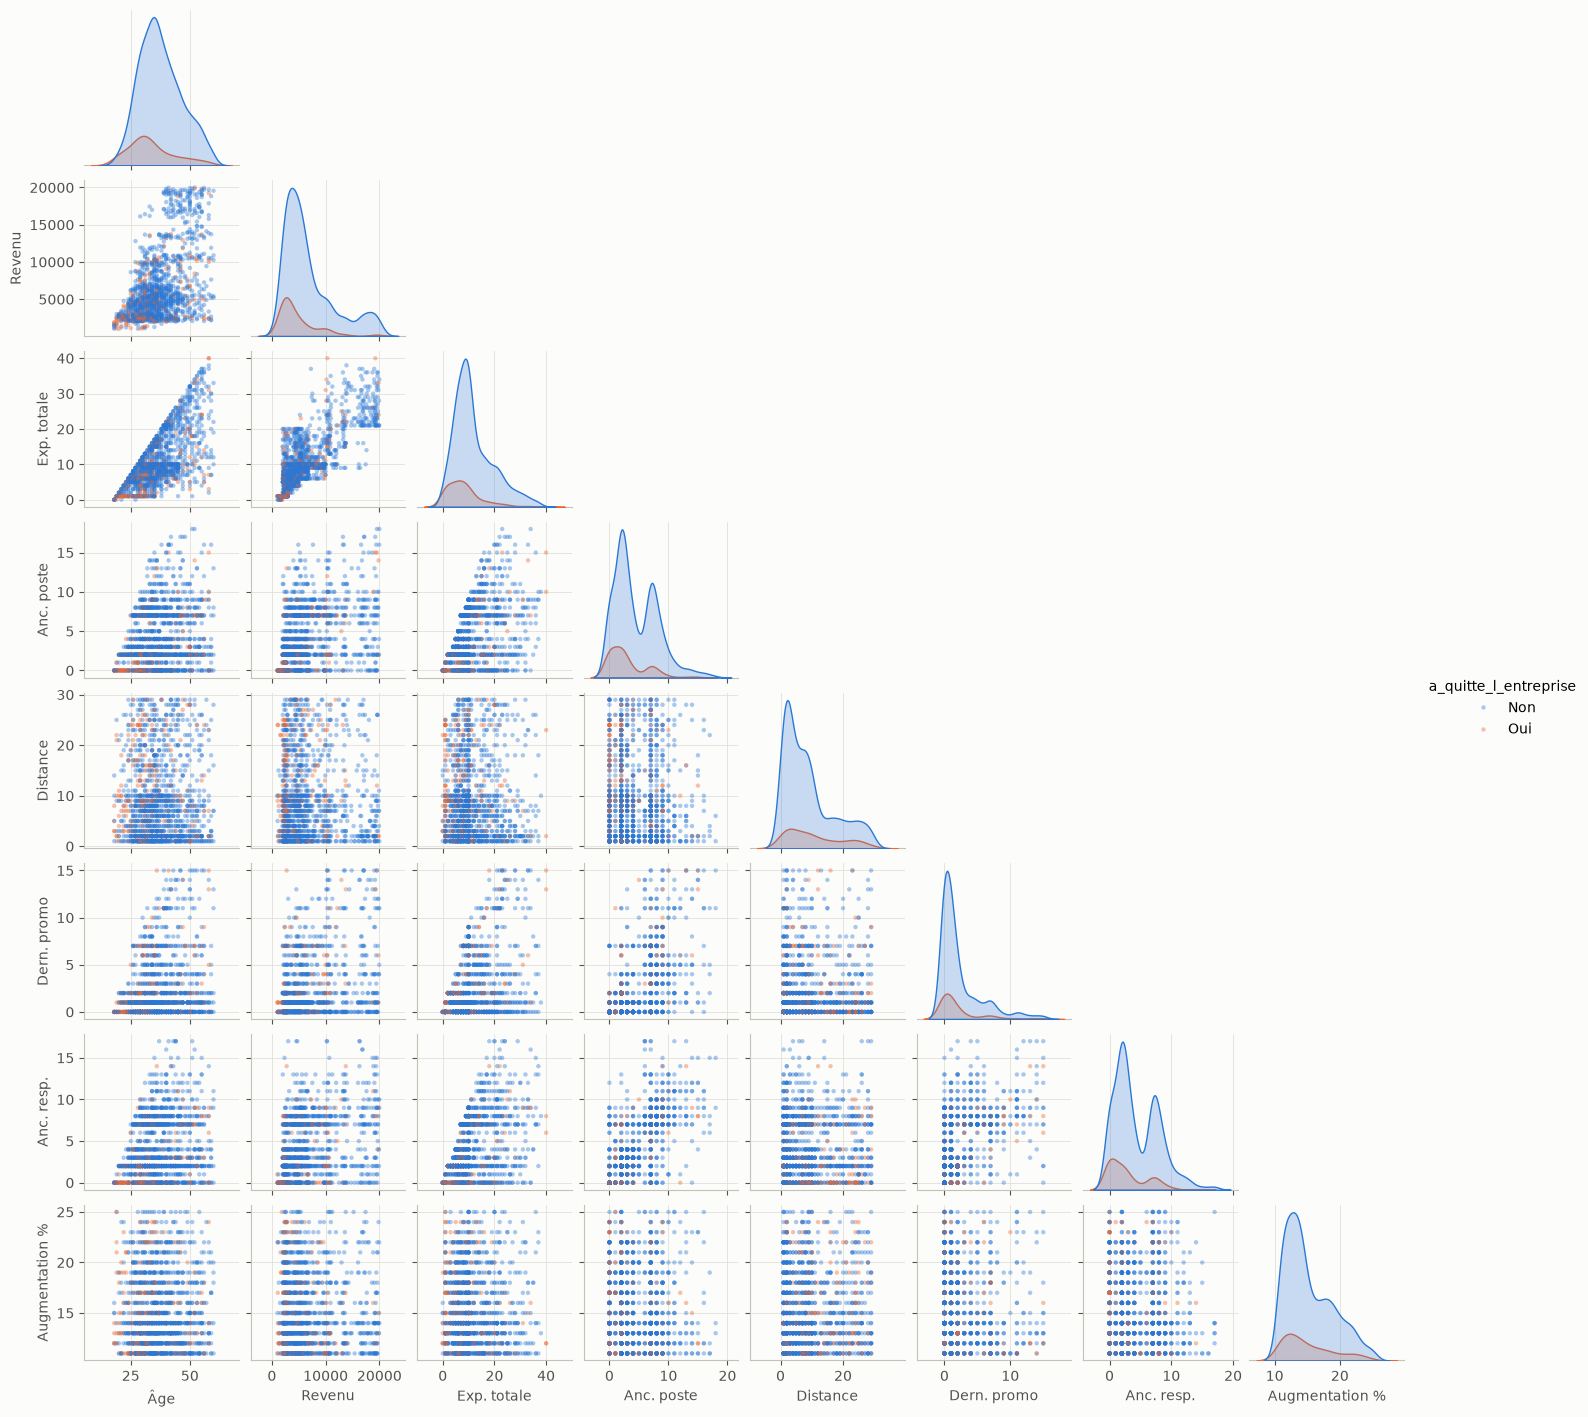

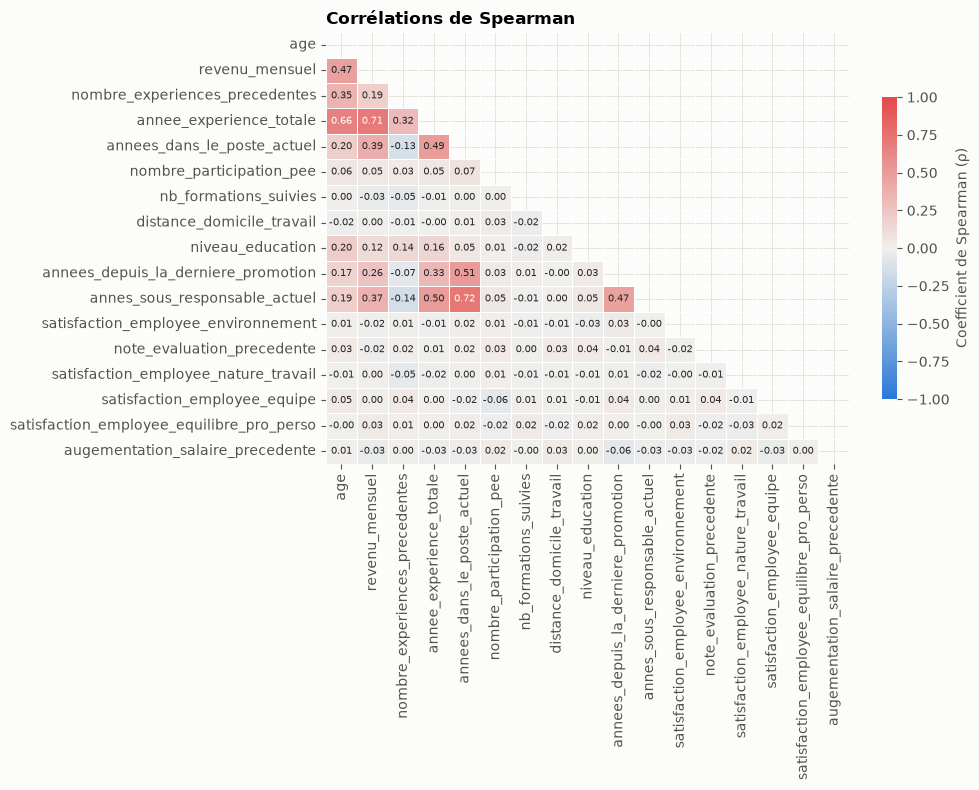

                                                                         pearson  spearman  ecart
revenu_mensuel                      annees_depuis_la_derniere_promotion     0.34      0.26  -0.08
nombre_experiences_precedentes      annee_experience_totale                 0.24      0.32   0.08
annee_experience_totale             annees_depuis_la_derniere_promotion     0.40      0.33  -0.07
revenu_mensuel                      annee_experience_totale                 0.77      0.71  -0.06
age                                 nombre_experiences_precedentes          0.30      0.35   0.05
annees_depuis_la_derniere_promotion annes_sous_responsable_actuel           0.51      0.47  -0.04
age                                 annees_depuis_la_derniere_promotion     0.22      0.17  -0.04
annee_experience_totale             nombre_participation_pee                0.01      0.05   0.04
annees_dans_le_poste_actuel         annees_depuis_la_derniere_promotion     0.55      0.51  -0.04
revenu_mensuel      

In [54]:
features_num = df_central.select_dtypes("number").columns.drop("id_employee")

# ---------- 1. Pairplot sur les variables continues ----------
nb_valeurs = df_central[features_num].nunique()
continues = nb_valeurs[nb_valeurs > 10].index.tolist()

noms_courts = {"age": "Âge", "revenu_mensuel": "Revenu", "annee_experience_totale": "Exp. totale",
               "annees_dans_le_poste_actuel": "Anc. poste", "distance_domicile_travail": "Distance",
               "annees_depuis_la_derniere_promotion": "Dern. promo",
               "annes_sous_responsable_actuel": "Anc. resp.",
               "augementation_salaire_precedente": "Augmentation %"}
data_plot = df_central[continues + ["a_quitte_l_entreprise"]].rename(columns=noms_courts)

g = sns.pairplot(data_plot, vars=[noms_courts.get(c, c) for c in continues],
                 hue="a_quitte_l_entreprise", hue_order=["Non", "Oui"],
                 palette={"Non": "#2a78d6", "Oui": "#eb6834"},
                 corner=True, diag_kind="kde",
                 plot_kws={"s": 10, "alpha": 0.4, "edgecolor": "none"}, height=1.8)
plt.show()

# ---------- 2. Matrice de Spearman ----------
spearman = df_central[features_num].corr(method="spearman")
masque = np.triu(np.ones(spearman.shape, dtype=bool))
cmap = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spearman, mask=masque, cmap=cmap, vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5,
            cbar_kws={"label": "Coefficient de Spearman (ρ)", "shrink": 0.7}, ax=ax)
ax.set_title("Corrélations de Spearman", loc="left", fontweight="bold")
fig.tight_layout()
plt.show()

# ---------- 3. Comparaison Spearman vs Pearson ----------
pearson = df_central[features_num].corr(method="pearson")
haut = np.triu(np.ones(spearman.shape, dtype=bool), k=1)
comp = pd.DataFrame({"pearson": pearson.where(haut).stack(),
                     "spearman": spearman.where(haut).stack()})
comp["ecart"] = comp["spearman"] - comp["pearson"]
print(comp.sort_values("ecart", key=abs, ascending=False).head(10).round(2))

#### Préparation de la donnée

In [55]:
# Cible (y) et features (X)
y = df_central["a_quitte_l_entreprise"].map({"Oui": 1, "Non": 0})
X = df_central.drop(columns=["id_employee", "a_quitte_l_entreprise"])

# Pipeline pour convertir les colonnes de textes en nombres (encodage)
nominales = ["statut_marital", "departement", "poste", "domaine_etude"]
binaires = ["genre", "heure_supplementaires"]
ordinales = ["frequence_deplacement"]
numeriques = X.select_dtypes("number").columns.tolist()
preprocesseur = ColumnTransformer([ # L’encodage et la mise à l’échelle seront appris uniquement sur le jeu d’entraînement
    ("nom", OneHotEncoder(drop="first", handle_unknown="ignore"), nominales), # ne plante pas si des modalités sont inconnues pendant le test
    ("bin", OneHotEncoder(drop="if_binary"), binaires),  # drop pour les suppressions de colonnes inutiles
    ("ord", OrdinalEncoder(categories=[["Aucun", "Occasionnel", "Frequent"]]), ordinales),
    ("num", StandardScaler(), numeriques),
])

modele = Pipeline([
    ("preprocessing", preprocesseur),
    ("classifieur", LogisticRegression(max_iter=1000)),
])
modele.fit(X, y)

# Affichage des features après preprocessing
print(preprocesseur.get_feature_names_out())
print(modele.named_steps["preprocessing"].get_feature_names_out().shape)  # 37

['nom__statut_marital_Divorcé(e)' 'nom__statut_marital_Marié(e)'
 'nom__departement_Consulting' 'nom__departement_Ressources Humaines'
 'nom__poste_Cadre Commercial' 'nom__poste_Consultant'
 'nom__poste_Directeur Technique' 'nom__poste_Manager'
 'nom__poste_Représentant Commercial' 'nom__poste_Ressources Humaines'
 'nom__poste_Senior Manager' 'nom__poste_Tech Lead'
 'nom__domaine_etude_Entrepreunariat' 'nom__domaine_etude_Infra & Cloud'
 'nom__domaine_etude_Marketing' 'nom__domaine_etude_Ressources Humaines'
 'nom__domaine_etude_Transformation Digitale' 'bin__genre_M'
 'bin__heure_supplementaires_Oui' 'ord__frequence_deplacement' 'num__age'
 'num__revenu_mensuel' 'num__nombre_experiences_precedentes'
 'num__annee_experience_totale' 'num__annees_dans_le_poste_actuel'
 'num__nombre_participation_pee' 'num__nb_formations_suivies'
 'num__distance_domicile_travail' 'num__niveau_education'
 'num__annees_depuis_la_derniere_promotion'
 'num__annes_sous_responsable_actuel'
 'num__satisfaction_e

#### Modélisation

In [63]:
# Cible (y) et features (X)
y = df_central["a_quitte_l_entreprise"].map({"Oui": 1, "Non": 0})
X = df_central.drop(columns=["id_employee", "a_quitte_l_entreprise"])

# Séparation train / test
# stratify=y : même proportion de départs (16 %) dans le train et dans le test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Pipeline pour convertir les colonnes de textes en nombres (encodage)
nominales = ["statut_marital", "departement", "poste", "domaine_etude"]
binaires = ["genre", "heure_supplementaires"]
ordinales = ["frequence_deplacement"]
numeriques = X.select_dtypes("number").columns.tolist()

def preprocesseur(scaler=True):
    return ColumnTransformer([ # L’encodage et la mise à l’échelle seront appris uniquement sur le jeu d’entraînement
        ("nom", OneHotEncoder(drop="first", handle_unknown="ignore"), nominales), # ne plante pas si des modalités sont inconnues pendant le test
        ("bin", OneHotEncoder(drop="if_binary"), binaires), # drop pour les suppressions de colonnes inutiles
        ("ord", OrdinalEncoder(categories=[["Aucun", "Occasionnel", "Frequent"]]), ordinales),
        ("num", StandardScaler() if scaler else "passthrough", numeriques),
    ])

modeles = {
    "Dummy": Pipeline([("prep", preprocesseur()),
                       ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Régression logistique": Pipeline([("prep", preprocesseur()),
                                       ("clf", LogisticRegression(max_iter=1000))]),
    "Random Forest": Pipeline([("prep", preprocesseur(scaler=False)),  # arbres : pas besoin de scaler
                               ("clf", RandomForestClassifier(n_estimators=300, random_state=42))]), # n_estimators = nombre d'arbres
}

metriques = ["accuracy", "balanced_accuracy", "recall", "precision", "f1", "roc_auc", "average_precision"]

# Validation croisée sur le train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lignes_cv = []
for nom, modele in modeles.items():
    scores = cross_validate(modele, X_train, y_train, cv=cv, scoring=metriques,
                            return_train_score=True)
    lignes_cv.append({"modele": nom, "jeu": "train",
                      **{m: scores[f"train_{m}"].mean() for m in metriques}})
    lignes_cv.append({"modele": nom, "jeu": "validation",   # "test_" = plis de validation
                      **{m: scores[f"test_{m}"].mean() for m in metriques}})

print("=== Validation croisée (5 plis, moyenne) ===")
print(pd.DataFrame(lignes_cv).set_index(["modele", "jeu"]).round(3).to_string())

# Évaluation finale : train complet vs test
def evaluer(modele, X, y):
    y_pred = modele.predict(X)
    y_proba = modele.predict_proba(X)[:, 1]
    return {
        "accuracy": accuracy_score(y, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y, y_pred),
        "recall": recall_score(y, y_pred, zero_division=0),
        "precision": precision_score(y, y_pred, zero_division=0),
        "f1": f1_score(y, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y, y_proba),
        "average_precision": average_precision_score(y, y_proba),
    }
lignes = []
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    for jeu, (Xs, ys) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        lignes.append({"modele": nom, "jeu": jeu, **evaluer(modele, Xs, ys)})
print("\n=== Évaluation finale : train vs test ===")
print(pd.DataFrame(lignes).set_index(["modele", "jeu"]).round(3).to_string())

# Rapport détaillé sur le test
for nom, modele in modeles.items():
    print(f"\n--- {nom} (test) ---")
    print(classification_report(y_test, modele.predict(X_test), target_names=["Resté", "Parti"], zero_division=0))

D:\Taf\Training\OpenClassrooms\Projets\Projet 4\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\Taf\Training\OpenClassrooms\Projets\Projet 4\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
D:\Taf\Training\OpenClassrooms\Projets\Projet 4\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

=== Validation croisée (5 plis, moyenne) ===
                                  accuracy  balanced_accuracy  recall  precision     f1  roc_auc  average_precision
modele                jeu                                                                                          
Dummy                 train          0.838              0.500   0.000      0.000  0.000    0.500              0.162
                      validation     0.838              0.500   0.000      0.000  0.000    0.500              0.162
Régression logistique train          0.900              0.731   0.482      0.831  0.609    0.875              0.721
                      validation     0.891              0.712   0.447      0.788  0.567    0.846              0.669
Random Forest         train          1.000              1.000   1.000      1.000  1.000    1.000              1.000
                      validation     0.866              0.601   0.211      0.871  0.325    0.824              0.589

=== Évaluation finale : tr


===== Dummy (test) =====
[[247   0]
 [ 47   0]]
              precision    recall  f1-score   support

       Resté       0.84      1.00      0.91       247
       Parti       0.00      0.00      0.00        47

    accuracy                           0.84       294
   macro avg       0.42      0.50      0.46       294
weighted avg       0.71      0.84      0.77       294


===== Régression logistique (test) =====
[[238   9]
 [ 30  17]]
              precision    recall  f1-score   support

       Resté       0.89      0.96      0.92       247
       Parti       0.65      0.36      0.47        47

    accuracy                           0.87       294
   macro avg       0.77      0.66      0.70       294
weighted avg       0.85      0.87      0.85       294


===== Random Forest (test) =====
[[242   5]
 [ 41   6]]
              precision    recall  f1-score   support

       Resté       0.86      0.98      0.91       247
       Parti       0.55      0.13      0.21        47

    accurac

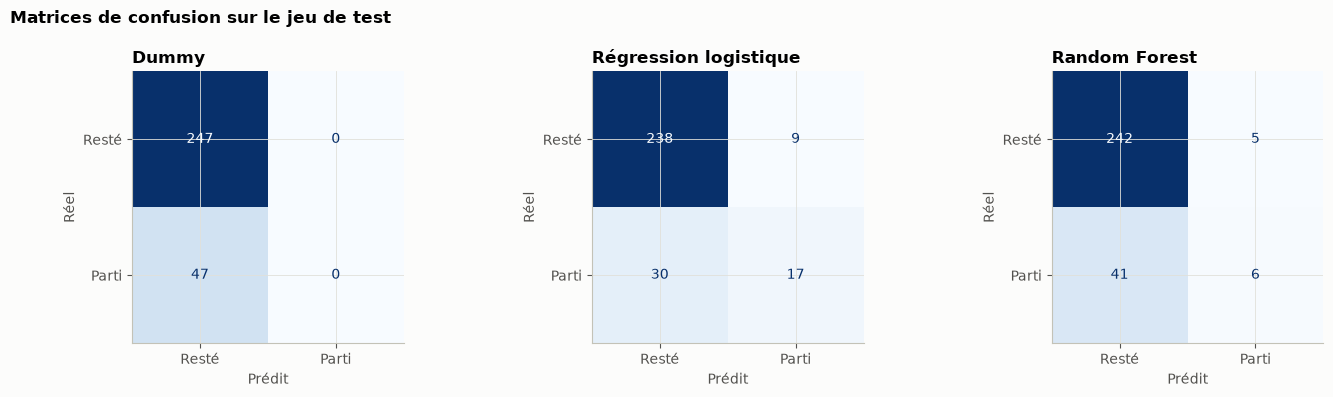

In [65]:
# Matrices de confusion et classification reports
for nom, modele in modeles.items():
    y_pred = modele.predict(X_test)
    print(f"\n===== {nom} (test) =====")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=["Resté", "Parti"], zero_division=0))

# Matrices de confusion en graphique
fig, axes = plt.subplots(1, len(modeles), figsize=(14, 4))
for ax, (nom, modele) in zip(axes, modeles.items()):
    ConfusionMatrixDisplay.from_estimator(
        modele, X_test, y_test, display_labels=["Resté", "Parti"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nom, loc="left", fontweight="bold")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
fig.suptitle("Matrices de confusion sur le jeu de test", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

### Optimisation et interprétation du modèle

X_train (1176, 31) | taux de départ 16.2%
X_test  (294, 31) | taux de départ 16.0%

Hyperparamètres retenus : {'clf__max_depth': 4, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 20}

=== Validation croisée (seuil 0,5) ===
                   train  validation  écart-type validation
roc_auc            0.900       0.804                  0.022
average_precision  0.692       0.547                  0.077
recall             0.734       0.532                  0.086
precision          0.571       0.467                  0.053
f1                 0.642       0.494                  0.059
balanced_accuracy  0.814       0.707                  0.039

Seuil retenu (F2 max en CV) : 0.41

=== Validation croisée au seuil retenu ===
              precision    recall  f1-score   support

       Resté       0.94      0.67      0.78       986
       Parti       0.32      0.78      0.45       190

    accuracy                           0.69      1176
   macro avg       0.63      0.73      0.62      117

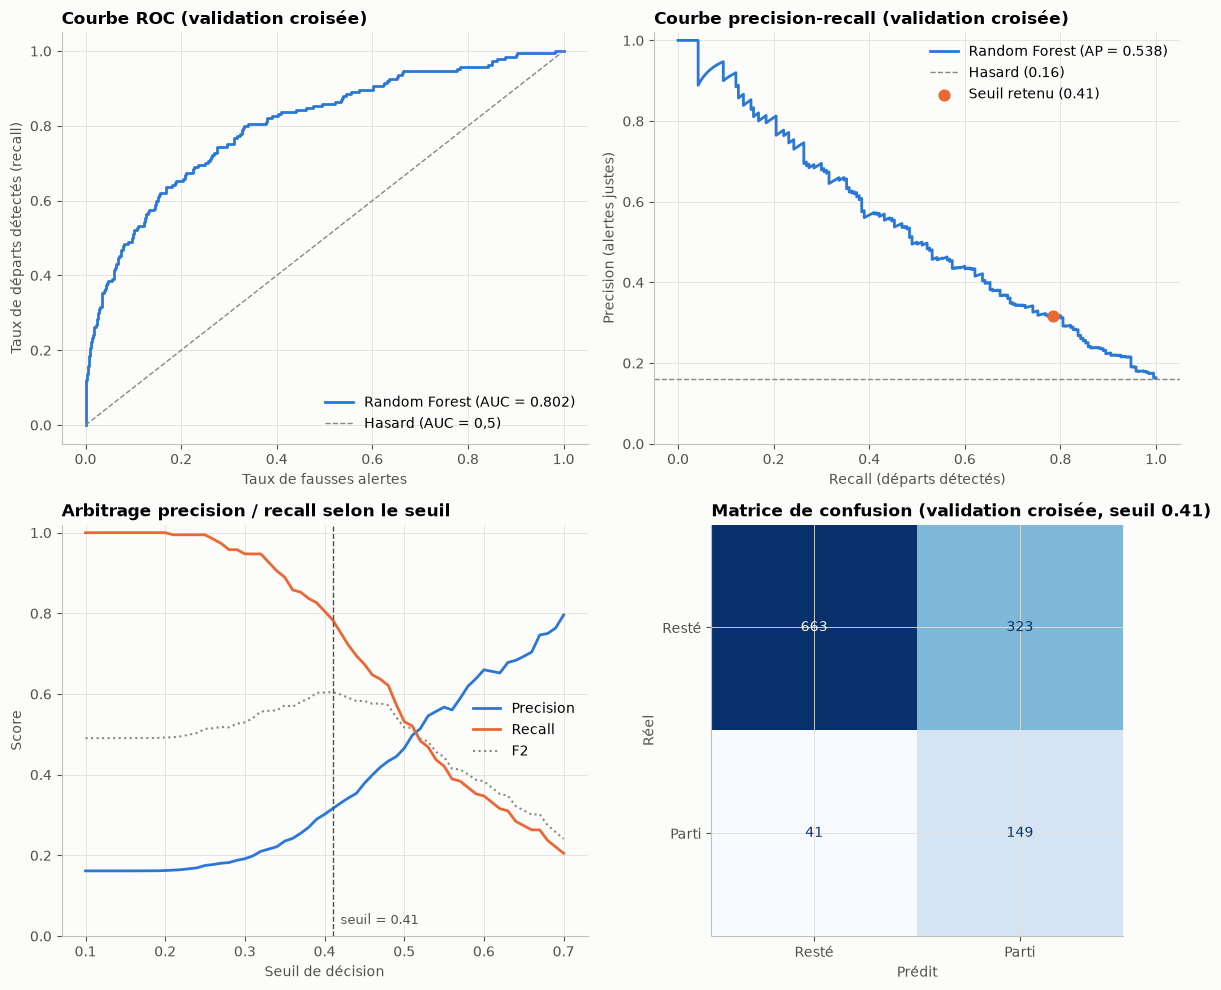

In [84]:
# Nouvelles features
satisfactions = ["satisfaction_employee_environnement", "satisfaction_employee_nature_travail", "satisfaction_employee_equipe", "satisfaction_employee_equilibre_pro_perso"]
df_central["satisfaction_moyenne"] = df_central[satisfactions].mean(axis=1)
df_central["satisfaction_min"] = df_central[satisfactions].min(axis=1) # au moins un point de mécontentement fort
df_central["revenu_par_annee_exp"] = df_central["revenu_mensuel"] / (df_central["annee_experience_totale"] + 1)
df_central["taux_mobilite"] = df_central["nombre_experiences_precedentes"] / (df_central["annee_experience_totale"] + 1)
df_central["age_debut_carriere"] = df_central["age"] - df_central["annee_experience_totale"]
df_central["part_poste_sans_promo"] = df_central["annees_depuis_la_derniere_promotion"] / (df_central["annees_dans_le_poste_actuel"] + 1)
df_central["surcharge"] = ((df_central["heure_supplementaires"] == "Oui") & (df_central["frequence_deplacement"] == "Frequent")).astype(int)
nouvelles_features = ["satisfaction_moyenne", "satisfaction_min", "revenu_par_annee_exp", "taux_mobilite", "age_debut_carriere", "part_poste_sans_promo", "surcharge"]

# Séparation train/test
y = df_central["a_quitte_l_entreprise"].map({"Oui": 1, "Non": 0})
X = df_central.drop(columns=["id_employee", "a_quitte_l_entreprise"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42) # stratifié grâce à stratify=y
print(f"X_train {X_train.shape} | taux de départ {y_train.mean():.1%}")
print(f"X_test  {X_test.shape} | taux de départ {y_test.mean():.1%}")

# Prétraitement + modèle non linéaire pondéré
nominales = ["statut_marital", "departement", "poste", "domaine_etude"]
binaires = ["genre", "heure_supplementaires"]
ordinales = ["frequence_deplacement"]
numeriques = X.select_dtypes("number").columns.tolist()

preprocesseur = ColumnTransformer([
    ("nom", OneHotEncoder(handle_unknown="ignore"), nominales),   # arbres : on garde toutes les modalités
    ("bin", OneHotEncoder(drop="if_binary"), binaires),
    ("ord", OrdinalEncoder(categories=[["Aucun", "Occasionnel", "Frequent"]]), ordinales),
    ("num", "passthrough", numeriques),                            # arbres : pas de mise à l'échelle
])

pipeline = Pipeline([
    ("prep", preprocesseur),
    ("clf", RandomForestClassifier(n_estimators=300,
                                   class_weight="balanced_subsample",  # déséquilibre des classes
                                   random_state=42, n_jobs=-1)),
])

# Réglage des hyperparamètres en validation croisée (contre l'overfit)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grille = {"clf__max_depth": [4, 6, 8, None],
          "clf__min_samples_leaf": [1, 5, 10, 20],
          "clf__max_features": ["sqrt", 0.5]}
def plus_simple_proche_du_meilleur(cv_results):
    """Règle d'un écart-type : parmi les combinaisons dont le score n'est pas
    significativement moins bon que le meilleur, on prend la plus régularisée."""
    r = pd.DataFrame(cv_results)
    meilleur = r["mean_test_score"].idxmax()
    plancher = r.loc[meilleur, "mean_test_score"] - r.loc[meilleur, "std_test_score"]
    candidats = r[r["mean_test_score"] >= plancher].copy()
    candidats["profondeur"] = candidats["param_clf__max_depth"].fillna(1000).astype(float)
    candidats = candidats.sort_values(["profondeur", "param_clf__min_samples_leaf", "mean_test_score"], ascending=[True, False, False])
    return candidats.index[0]

recherche = GridSearchCV(pipeline, grille, cv=cv, scoring="average_precision", n_jobs=-1,
                         refit=plus_simple_proche_du_meilleur)
recherche.fit(X_train, y_train)
modele = recherche.best_estimator_
print("\nHyperparamètres retenus :", recherche.best_params_)

# Métriques en validation croisée (train vs validation)
metriques = ["roc_auc", "average_precision", "recall", "precision", "f1", "balanced_accuracy"]
scores = cross_validate(modele, X_train, y_train, cv=cv, scoring=metriques, return_train_score=True)
tableau_cv = pd.DataFrame({
    "train": {m: scores[f"train_{m}"].mean() for m in metriques},
    "validation": {m: scores[f"test_{m}"].mean() for m in metriques},
    "écart-type validation": {m: scores[f"test_{m}"].std() for m in metriques},
}).round(3)
print("\n=== Validation croisée (seuil 0,5) ===")
print(tableau_cv.to_string())

# Choix du seuil selon le métier : rater un départ coûte plus qu'une fausse alerte
#    -> on maximise le F2 (le recall compte 2 fois plus que la precision)
#    sur les probabilités "hors pli" de la validation croisée (jamais sur le test)
proba_cv = cross_val_predict(modele, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
seuils = np.arange(0.10, 0.71, 0.01)
f2 = [fbeta_score(y_train, (proba_cv >= s).astype(int), beta=2) for s in seuils]
seuil = round(float(seuils[int(np.argmax(f2))]), 2)
print(f"\nSeuil retenu (F2 max en CV) : {seuil}")

pred_cv = (proba_cv >= seuil).astype(int)
print("\n=== Validation croisée au seuil retenu ===")
print(classification_report(y_train, pred_cv, target_names=["Resté", "Parti"]))

# Stockage des métriques par fold
def calculer_metriques(y_vrai, proba, seuil):
    y_pred = (proba >= seuil).astype(int)
    return {
        "roc_auc": roc_auc_score(y_vrai, proba),
        "pr_auc": average_precision_score(y_vrai, proba),
        "recall": recall_score(y_vrai, y_pred, zero_division=0),
        "precision": precision_score(y_vrai, y_pred, zero_division=0),
        "f1": f1_score(y_vrai, y_pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_vrai, y_pred),
    }

# Une liste par jeu : on y ajoute les métriques de chaque fold
metriques_train, metriques_validation = [], []

for i, (idx_train, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    X_tr, X_val = X_train.iloc[idx_train], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_train], y_train.iloc[idx_val]

    modele_fold = clone(modele)          # modèle neuf, non entraîné, à chaque fold
    modele_fold.fit(X_tr, y_tr)

    metriques_train.append({"fold": i, **calculer_metriques(
        y_tr, modele_fold.predict_proba(X_tr)[:, 1], seuil)})
    metriques_validation.append({"fold": i, **calculer_metriques(
        y_val, modele_fold.predict_proba(X_val)[:, 1], seuil)})

df_train = pd.DataFrame(metriques_train).set_index("fold")
df_val = pd.DataFrame(metriques_validation).set_index("fold")

print("=== Validation : métriques par fold ===")
print(df_val.round(3).to_string())

resume = pd.DataFrame({
    "train moyenne": df_train.mean(),
    "train écart-type": df_train.std(),
    "validation moyenne": df_val.mean(),
    "validation écart-type": df_val.std(),
    "écart train - validation": df_train.mean() - df_val.mean(),
}).round(3)
print(f"\n=== Résumé sur les {cv.get_n_splits()} folds (seuil {seuil}) ===")
print(resume.to_string())

# Évaluation finale sur le test (modèle entraîné sur tout le train)
modele.fit(X_train, y_train)
proba_test = modele.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= seuil).astype(int)
print(f"=== Test === ROC AUC {roc_auc_score(y_test, proba_test):.3f} | "
      f"PR AUC {average_precision_score(y_test, proba_test):.3f}")
print(classification_report(y_test, pred_test, target_names=["Resté", "Parti"]))

# Graphiques d'évaluation (validation croisée)
BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#898781"
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Courbe ROC
fpr, tpr, _ = roc_curve(y_train, proba_cv)
ax = axes[0, 0]
ax.plot(fpr, tpr, color=BLEU, lw=2, label=f"Random Forest (AUC = {roc_auc_score(y_train, proba_cv):.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1, label="Hasard (AUC = 0,5)")
ax.set(xlabel="Taux de fausses alertes", ylabel="Taux de départs détectés (recall)")
ax.set_title("Courbe ROC (validation croisée)", loc="left", fontweight="bold")
ax.legend(loc="lower right", frameon=False)

# Courbe precision-recall
prec, rec, _ = precision_recall_curve(y_train, proba_cv)
ax = axes[0, 1]
ax.plot(rec, prec, color=BLEU, lw=2, label=f"Random Forest (AP = {average_precision_score(y_train, proba_cv):.3f})")
ax.axhline(y_train.mean(), color=GRIS, ls="--", lw=1, label=f"Hasard ({y_train.mean():.2f})")
ax.scatter(recall_score(y_train, pred_cv), precision_score(y_train, pred_cv),
           color=ORANGE, s=60, zorder=3, label=f"Seuil retenu ({seuil})")
ax.set(xlabel="Recall (départs détectés)", ylabel="Precision (alertes justes)", ylim=(0, 1.02))
ax.set_title("Courbe precision-recall (validation croisée)", loc="left", fontweight="bold")
ax.legend(loc="upper right", frameon=False)

# Precision / recall selon le seuil
ax = axes[1, 0]
ax.plot(seuils, [precision_score(y_train, (proba_cv >= s).astype(int), zero_division=0) for s in seuils],
        color=BLEU, lw=2, label="Precision")
ax.plot(seuils, [recall_score(y_train, (proba_cv >= s).astype(int)) for s in seuils],
        color=ORANGE, lw=2, label="Recall")
ax.plot(seuils, f2, color=GRIS, lw=1.5, ls=":", label="F2")
ax.axvline(seuil, color="#52514e", lw=1, ls="--")
ax.text(seuil + 0.01, 0.03, f"seuil = {seuil}", color="#52514e", fontsize=9)
ax.set(xlabel="Seuil de décision", ylabel="Score", ylim=(0, 1.02))
ax.set_title("Arbitrage precision / recall selon le seuil", loc="left", fontweight="bold")
ax.legend(loc="center right", frameon=False)

# Matrice de confusion au seuil retenu
ConfusionMatrixDisplay(confusion_matrix(y_train, pred_cv), display_labels=["Resté", "Parti"]).plot(
    ax=axes[1, 1], cmap="Blues", colorbar=False)
axes[1, 1].set(xlabel="Prédit", ylabel="Réel")
axes[1, 1].set_title(f"Matrice de confusion (validation croisée, seuil {seuil})", loc="left", fontweight="bold")

for ax in axes.flat[:3]:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e1e0d9", lw=0.6)
fig.tight_layout()
plt.show()

# Feature importances study

In [ ]:
# Les features les plus utilisées par le modèle (Hyper paramètres faits plus hauts)
importances = pd.Series(modele.named_steps["clf"].feature_importances_,
                        index=modele.named_steps["prep"].get_feature_names_out()).sort_values()
importances.index = importances.index.str.replace(r"^\w+__", "", regex=True)
fig, ax = plt.subplots(figsize=(8, 6))
top = importances.tail(15)
ax.barh(top.index, top.values,
        color=[ORANGE if f in nouvelles_features else BLEU for f in top.index], height=0.6)
ax.set_xlabel("Importance (baisse moyenne d'impureté)")
ax.set_title("15 features les plus importantes (orange = features créées)", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9", lw=0.6)
fig.tight_layout()
plt.show()

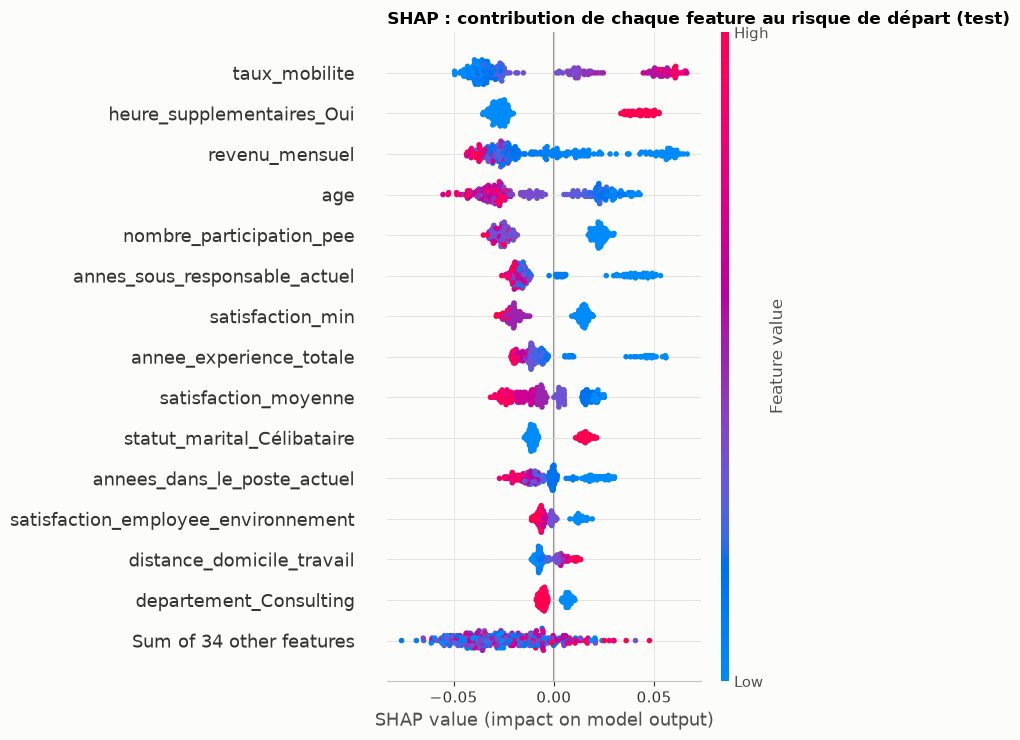

                                           native  permutation    shap  rang_native  rang_permutation  rang_shap  rang_moyen
heure_supplementaires                      0.0753       0.0819  0.0315            4                 1          2         2.3
revenu_mensuel                             0.1029       0.0111  0.0280            2                 3          3         2.7
nombre_participation_pee                   0.0544       0.0236  0.0247            7                 2          5         4.7
age                                        0.0803       0.0034  0.0268            3                 8          4         5.0
statut_marital                             0.0380       0.0097  0.0175           11                 4          8         7.7
satisfaction_min                           0.0350       0.0055  0.0178           12                 6          7         8.3
taux_mobilite                              0.1180      -0.0071  0.0360            1                28          1        10.0


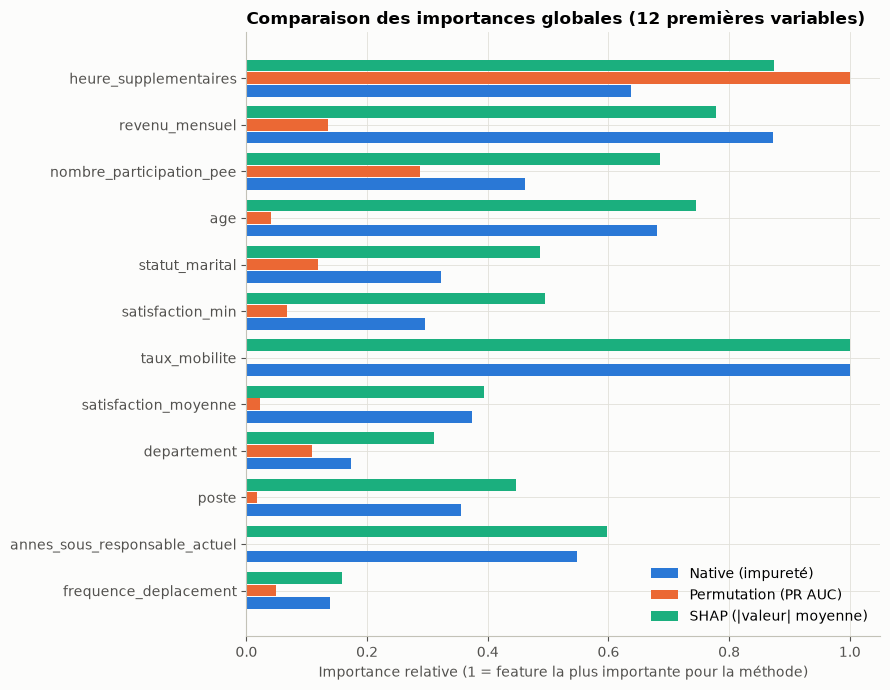

In [87]:
# Le modèle final (entraîné sur tout X_train) est découpé en ses deux étapes
prep = modele.named_steps["prep"]
rf = modele.named_steps["clf"]

# Features après encodage, avec des noms lisibles ("nom__poste_Consultant" -> "poste_Consultant")
X_test_enc = pd.DataFrame(prep.transform(X_test),
                          columns=prep.get_feature_names_out(), index=X_test.index)
X_test_enc.columns = X_test_enc.columns.str.replace(r"^\w+?__", "", regex=True)

# Pour comparer les méthodes, on ramène chaque colonne encodée à sa variable d'origine
# (ex. poste_Consultant, poste_Manager... -> poste)
categorielles = nominales + binaires
def variable_origine(nom_encode):
    if nom_encode in X_test.columns:              # variable numérique ou ordinale : nom inchangé
        return nom_encode
    for col in categorielles:                     # variable one-hot : "poste_Manager" -> "poste"
        if nom_encode.startswith(col + "_"):
            return col
origine = {c: variable_origine(c) for c in X_test_enc.columns}

# ---------- 1. Importance native de la forêt (impureté, calculée sur le train) ----------
imp_native = (pd.Series(rf.feature_importances_, index=X_test_enc.columns)
              .groupby(origine).sum())

# ---------- 2. Permutation importance (sklearn), sur le test ----------
# On mélange une variable d'origine et on mesure la baisse de PR AUC
perm = permutation_importance(modele, X_test, y_test, scoring="average_precision",
                              n_repeats=30, random_state=42, n_jobs=-1)
imp_perm = pd.Series(perm.importances_mean, index=X_test.columns)
imp_perm_std = pd.Series(perm.importances_std, index=X_test.columns)

# ---------- 3. SHAP avec TreeExplainer, sur le test ----------
explainer = shap.TreeExplainer(rf)
explication = explainer(X_test_enc)
explication_parti = explication[:, :, 1]          # contributions à la classe "Parti"

plt.figure()   # nouvelle figure, pour ne pas dessiner sur le graphique précédent
shap.plots.beeswarm(explication_parti, max_display=15, show=False)
plt.title("SHAP : contribution de chaque feature au risque de départ (test)", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

imp_shap = (pd.DataFrame(np.abs(explication_parti.values), columns=X_test_enc.columns)
            .mean().groupby(origine).sum())

# ---------- 4. Comparaison des trois méthodes ----------
comparaison = pd.DataFrame({"native": imp_native, "permutation": imp_perm, "shap": imp_shap})
rangs = comparaison.rank(ascending=False).astype(int).add_prefix("rang_")
comparaison = pd.concat([comparaison.round(4), rangs], axis=1)
comparaison["rang_moyen"] = rangs.mean(axis=1).round(1)
comparaison = comparaison.sort_values("rang_moyen")
print(comparaison.to_string())

print("\nCorrélation des classements (Spearman) :")
print(rangs.corr(method="spearman").round(2))

# ---------- 5. Graphique comparatif (top 12, chaque importance ramenée à 1 pour son max) ----------
top = comparaison.head(12).index[::-1]
normalisee = comparaison.loc[top, ["native", "permutation", "shap"]].clip(lower=0)
normalisee = normalisee / normalisee.max()
fig, ax = plt.subplots(figsize=(9, 7))
y_pos = np.arange(len(top))
for k, (col, couleur, label) in enumerate([("native", "#2a78d6", "Native (impureté)"),
                                           ("permutation", "#eb6834", "Permutation (PR AUC)"),
                                           ("shap", "#1baf7e", "SHAP (|valeur| moyenne)")]):
    ax.barh(y_pos + (k - 1) * 0.27, normalisee[col], height=0.25, color=couleur, label=label)
ax.set_yticks(y_pos, top)
ax.set_xlabel("Importance relative (1 = feature la plus importante pour la méthode)")
ax.set_title("Comparaison des importances globales (12 premières variables)", loc="left", fontweight="bold")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e1e0d9", lw=0.6)
fig.tight_layout()
plt.show()


=== Départ bien détecté (vrai positif) : employé 959 | probabilité de départ 0.84 | seuil 0.41 ===


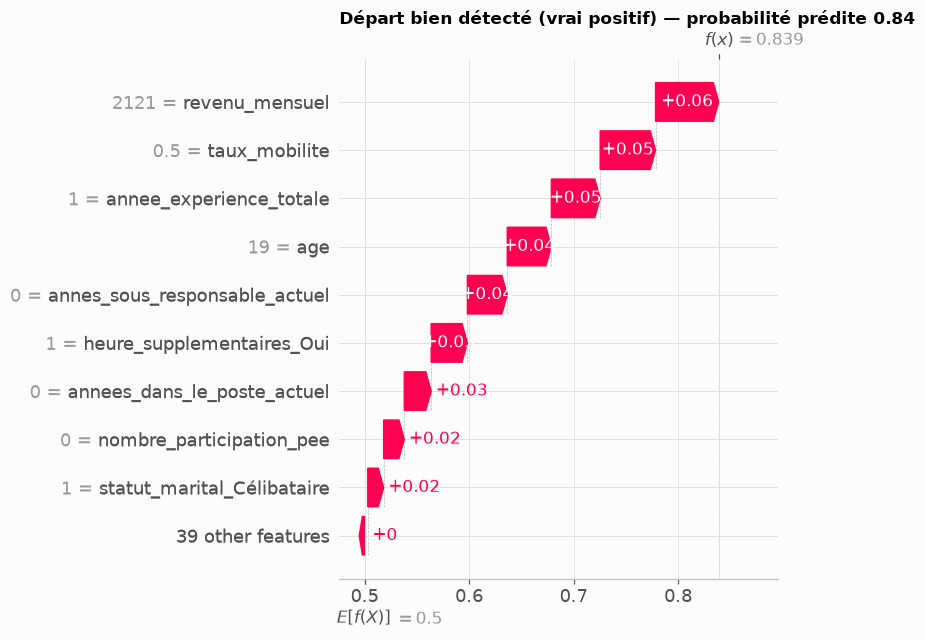


=== Fausse alerte (faux positif) : employé 411 | probabilité de départ 0.82 | seuil 0.41 ===


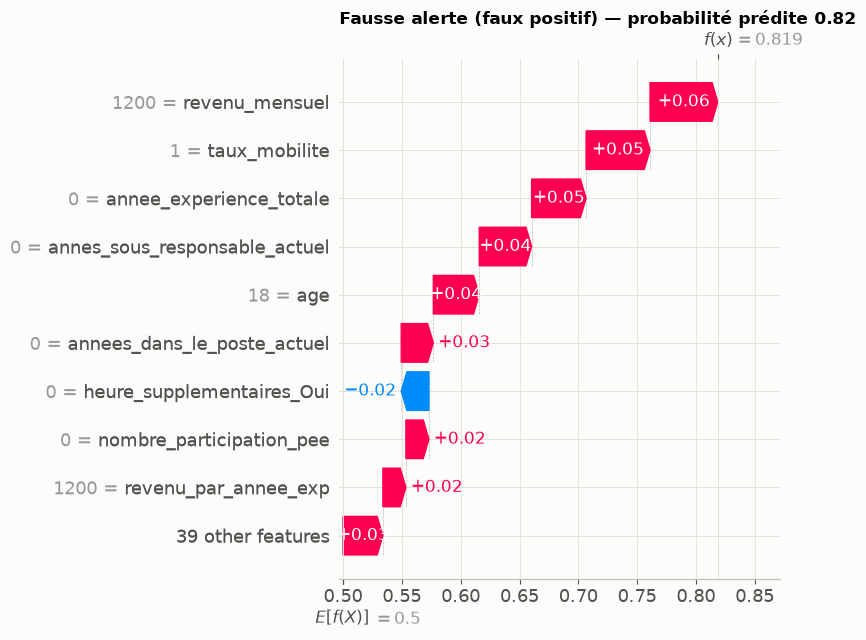


=== Départ raté (faux négatif) : employé 1572 | probabilité de départ 0.20 | seuil 0.41 ===


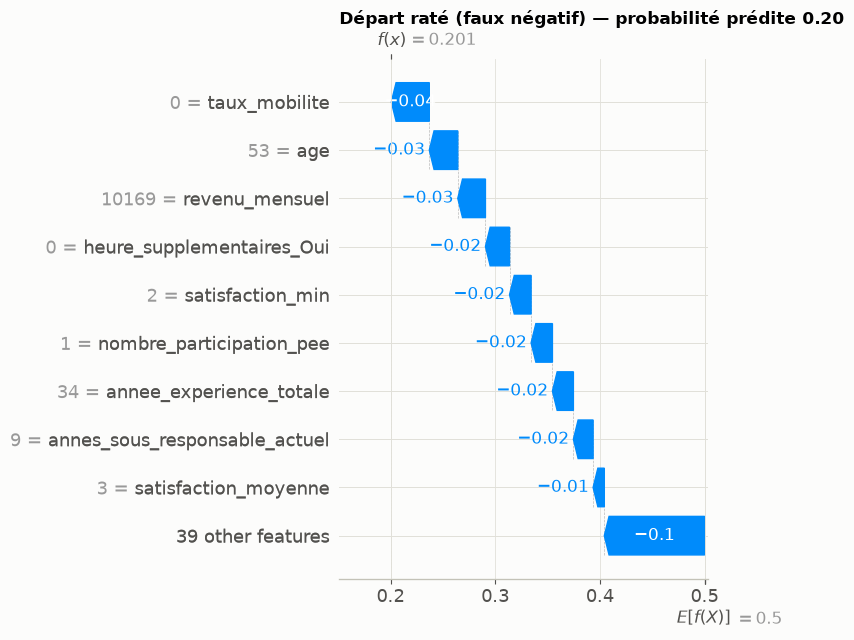

In [88]:
# Feature importance locale sur 3 salariés
resultats_test = pd.DataFrame({"reel": y_test.values, "proba": proba_test,
                               "predit": pred_test}, index=X_test.index)

# Trois cas typiques, pris dans le jeu de test
cas = {
    "Départ bien détecté (vrai positif)":
        resultats_test.query("reel == 1 and predit == 1")["proba"].idxmax(),
    "Fausse alerte (faux positif)":
        resultats_test.query("reel == 0 and predit == 1")["proba"].idxmax(),
    "Départ raté (faux négatif)":
        resultats_test.query("reel == 1 and predit == 0")["proba"].idxmin(),
}

for titre, idx in cas.items():
    i = X_test.index.get_loc(idx)                 # position de l'employé dans X_test
    r = resultats_test.loc[idx]
    print(f"\n=== {titre} : employé {df_central.loc[idx, 'id_employee']} | "
          f"probabilité de départ {r['proba']:.2f} | seuil {seuil} ===")

    plt.figure()
    shap.plots.waterfall(explication_parti[i], max_display=10, show=False)
    plt.title(f"{titre} — probabilité prédite {r['proba']:.2f}", loc="left", fontweight="bold")
    plt.tight_layout()
    plt.show()

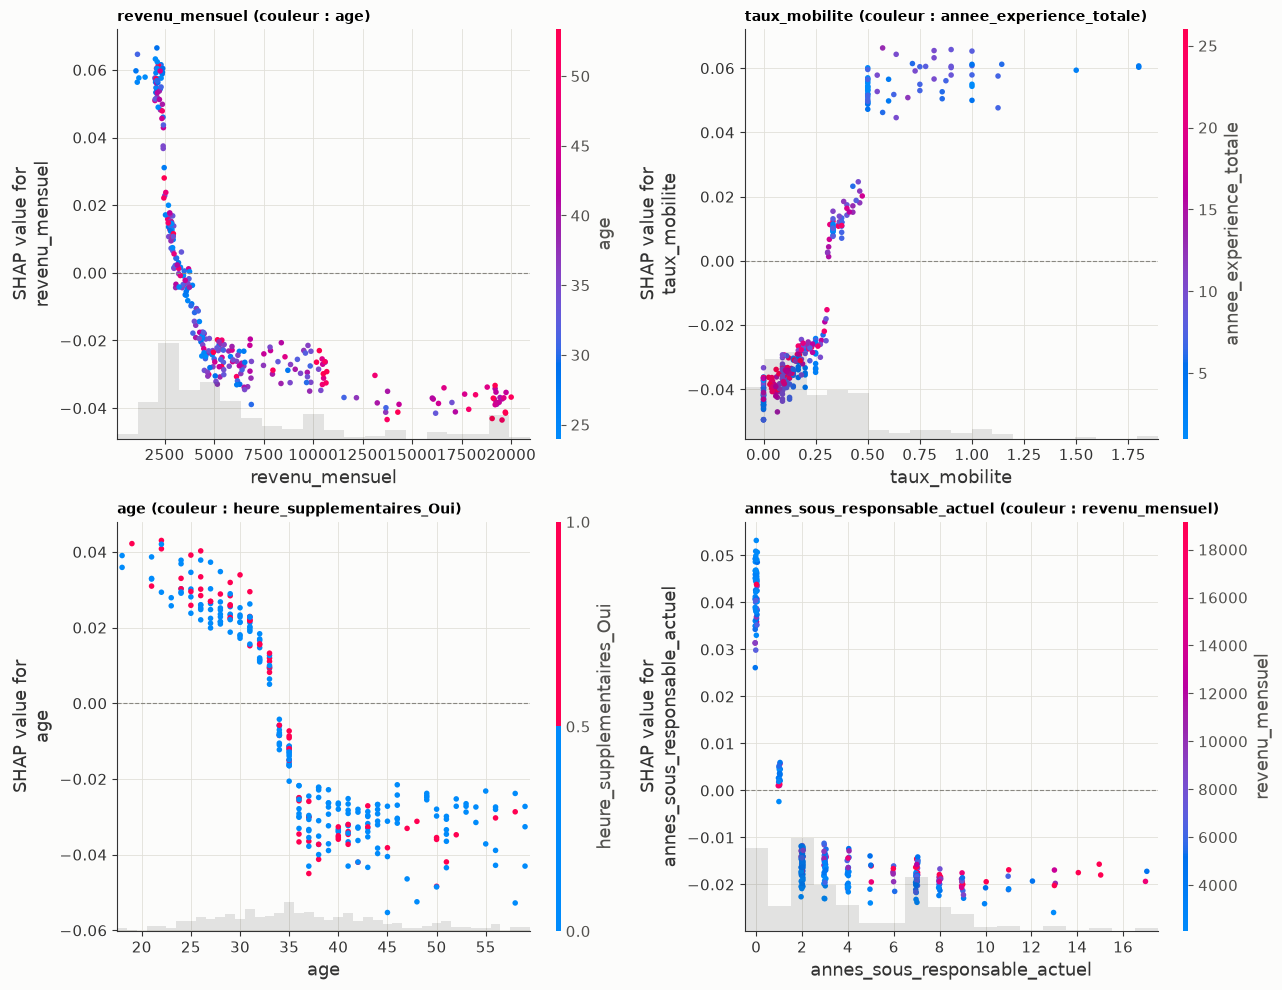

<Figure size 640x480 with 0 Axes>

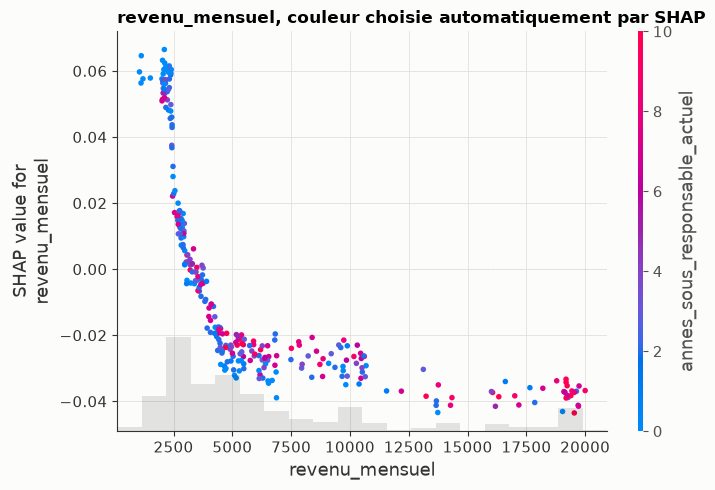

In [89]:
# ---------- Dependence plots SHAP : effet d'une feature, coloré par une autre ----------
paires = [
    ("revenu_mensuel", "age"),
    ("taux_mobilite", "annee_experience_totale"),
    ("age", "heure_supplementaires_Oui"),
    ("annes_sous_responsable_actuel", "revenu_mensuel"),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (feature, couleur) in zip(axes.flat, paires):
    shap.plots.scatter(explication_parti[:, feature],
                       color=explication_parti[:, couleur],
                       ax=ax, show=False)
    ax.axhline(0, color="#898781", lw=0.8, ls="--")
    ax.set_title(f"{feature} (couleur : {couleur})", loc="left", fontweight="bold", fontsize=10)
fig.tight_layout()
plt.show()

# Variante : color=explication_parti -> SHAP choisit la feature qui interagit le plus
plt.figure()
shap.plots.scatter(explication_parti[:, "revenu_mensuel"], color=explication_parti, show=False)
plt.title("revenu_mensuel, couleur choisie automatiquement par SHAP", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()